In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
url = "https://api.artic.edu/api/v1/artworks/search"

parameters = {"q": "Impressionism", "limit": 50, "fields": "id,title,artist_title,date_display,classification_title,is_public_domain"}

response = requests.get(url, params=parameters, timeout=30)
response.raise_for_status()

data = response.json()

print("API request successful!")
print("Total matching results:", data["pagination"]["total"])
print("Results retrieved:", len(data["data"]))

API request successful!
Total matching results: 133170
Results retrieved: 50


In [4]:
artworks = pd.DataFrame(data["data"])

artworks = artworks.rename(columns={"id": "Artwork ID", "title": "Title", "artist_title": "Artist", "date_display": "Date", "classification_title": "Classification", "is_public_domain": "Public Domain"})

artworks.head(10)

,_score,Artwork ID,Title,Date,Public Domain,Artist,Classification
0,65.025470,64729,"Early Morning, Tarpon Springs",1892,True,George Inness,painting
1,61.399727,71562,Sunlight,c. 1913,False,Richard E. Miller,painting
2,59.221820,138,Flower Girl in Holland,1887,True,George Hitchcock,painting
3,58.083443,70065,Afterglow,c. 1913,False,Jonas Lie,painting
4,57.941833,90899,Lady in Green and Gray,1911,False,Thomas Wilmer Dewing,oil on canvas
5,56.564316,27992,A Sunday on La Grande Jatte — 1884,"1884–86, border added 1888–89",True,Georges Seurat,oil on canvas
6,56.562992,13763,Snow-Crowned Hills,c. 1920,False,Guy Carleton Wiggins,painting
7,55.641052,71573,A Holiday,c. 1915,True,Edward Henry Potthast,painting
8,55.500854,17229,The Scream,1895,True,Edvard Munch,lithograph
9,54.239040,4749,Mrs. George Swinton (Elizabeth Ebsworth),1897,True,John Singer Sargent,painting


In [5]:
classification_counts = (artworks["Classification"] .fillna("Unknown") .value_counts())

print("Number of unique classifications:", len(classification_counts))

classification_counts.head(10)

Number of unique classifications: 5


Classification
painting         42
oil on canvas     5
lithograph        1
drypoint          1
woodcut           1
Name: count, dtype: int64

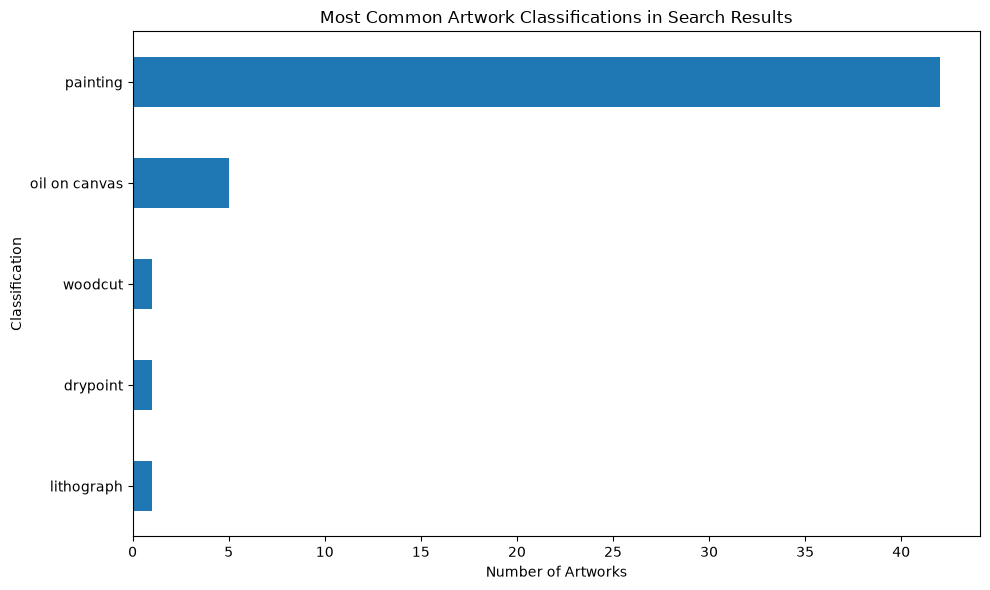

In [6]:
classification_counts.head(10).sort_values().plot(kind="barh", figsize=(10, 6))

plt.title("Most Common Artwork Classifications in Search Results")
plt.xlabel("Number of Artworks")
plt.ylabel("Classification")
plt.tight_layout()
plt.show()

Public Domain
True     31
False    19
Name: count, dtype: int64


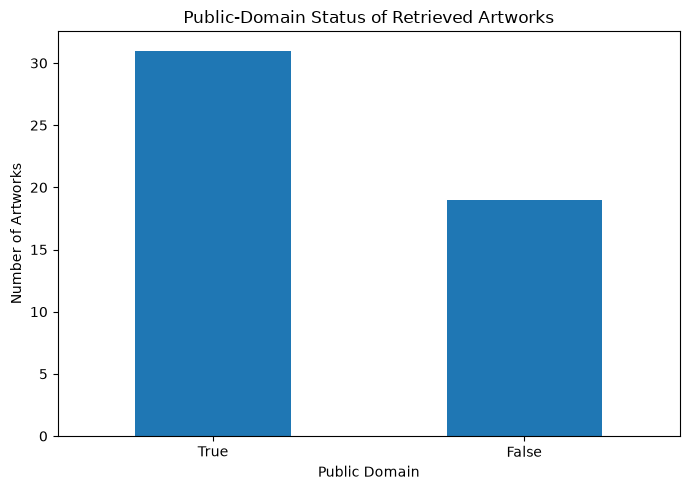

In [7]:
domain_counts = artworks["Public Domain"].value_counts()

print(domain_counts)

domain_counts.plot(kind="bar", figsize=(7, 5))

plt.title("Public-Domain Status of Retrieved Artworks")
plt.xlabel("Public Domain")
plt.ylabel("Number of Artworks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The API for The Art Institute of Chicago was used to analyze and explore artwork from the museums collection. This is an efficient method for people in the modern world to obtain information or data using code instead of searching through it manually. 